# 01 - Dataset Preparation

This notebook loads and prepares the Fashion-MNIST dataset
for all generative model experiments.

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt

from torchvision import datasets
from sklearn.model_selection import train_test_split
from pathlib import Path

In [3]:
PROJECT_DIR = Path.cwd()

if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

DATA_DIR = PROJECT_DIR / "data"
DATA_DIR.mkdir(exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Data directory:", DATA_DIR)

Project directory: d:\generative-models-comparison
Data directory: d:\generative-models-comparison\data


In [4]:
DATASET_DIR = DATA_DIR / "fashion_mnist"

# Download training dataset
train_dataset = datasets.FashionMNIST(
    root=DATASET_DIR,
    train=True,
    download=True
)

# Download testing dataset
test_dataset = datasets.FashionMNIST(
    root=DATASET_DIR,
    train=False,
    download=True
)

print("Training data:", len(train_dataset))
print("Testing data:", len(test_dataset))

100%|██████████| 26.4M/26.4M [00:04<00:00, 5.94MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 162kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 2.64MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 5.14MB/s]

Training data: 60000
Testing data: 10000


In [5]:
# Combine training and testing images
all_images = torch.cat([
    train_dataset.data,
    test_dataset.data
])

# Combine labels
all_labels = torch.cat([
    train_dataset.targets,
    test_dataset.targets
])

print("Total images:", len(all_images))
print("Image shape:", all_images.shape)
print("Total labels:", len(all_labels))

Total images: 70000
Image shape: torch.Size([70000, 28, 28])
Total labels: 70000


In [6]:
# Create dataset indices
indices = np.arange(len(all_images))

# Split training data (80%) and temporary data (20%)
train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.2,
    random_state=42,
    stratify=all_labels.numpy()
)

# Split temporary data into validation (10%) and testing (10%)
val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.5,
    random_state=42,
    stratify=all_labels[temp_idx].numpy()
)

# Display dataset sizes
print("Training samples:", len(train_idx))
print("Validation samples:", len(val_idx))
print("Testing samples:", len(test_idx))

Training samples: 56000
Validation samples: 7000
Testing samples: 7000


In [7]:
# Create dataset splits
train_images = all_images[train_idx]
train_labels = all_labels[train_idx]

val_images = all_images[val_idx]
val_labels = all_labels[val_idx]

test_images = all_images[test_idx]
test_labels = all_labels[test_idx]

# Check dataset shapes
print("Train shape:", train_images.shape)
print("Validation shape:", val_images.shape)
print("Test shape:", test_images.shape)

Train shape: torch.Size([56000, 28, 28])
Validation shape: torch.Size([7000, 28, 28])
Test shape: torch.Size([7000, 28, 28])


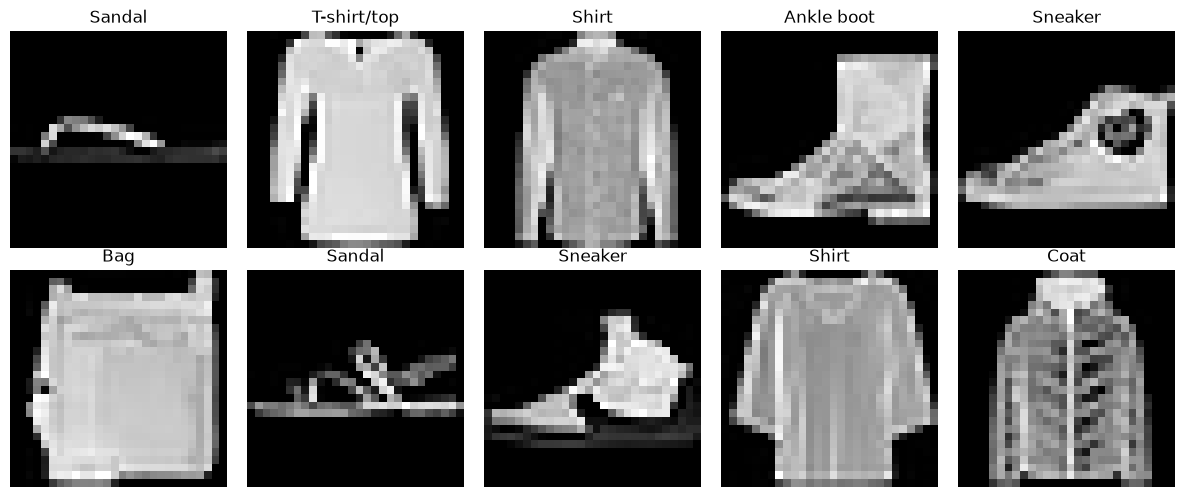

In [8]:
# Define Fashion-MNIST class names
class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

# Display sample images
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(train_images[i], cmap="gray")
    plt.title(class_names[train_labels[i].item()])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [10]:
# Save dataset splits
dataset_splits = {
    "train_images": train_images,
    "train_labels": train_labels,
    "val_images": val_images,
    "val_labels": val_labels,
    "test_images": test_images,
    "test_labels": test_labels
}

torch.save(
    dataset_splits,
    DATASET_DIR / "fashion_mnist_splits.pt"
)

In [11]:
# Check saved dataset file
saved_file = DATASET_DIR / "fashion_mnist_splits.pt"

print("File exists:", saved_file.exists())
print("File size:", saved_file.stat().st_size / (1024 * 1024), "MB")

File exists: True
File size: 52.874680519104004 MB
